# Automated Web Security Scanner
**Project:** Automated Web Scanner — audits websites for missing security headers and CORS misconfigurations
**Author:** Arati V Salgaonkar
**Program:** IBM SkillsBuild National Cybersecurity Bootcamp (BharatCares)

### What this notebook does
1. Takes a list of URLs.
2. Sends a request to each site and checks 6 important **security headers**.
3. Runs a basic **CORS** test using a fake `Origin` header.
4. Gives each site a **score (0-100)** and a **grade (A-F)**.
5. Shows a results table, a bar chart and saves a CSV report.

> **Ethical use:** Only scan websites you own or that are meant for testing. This tool only sends normal GET requests (no attacks, no brute force).

## 1. Import libraries

In [11]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
from urllib.parse import urlparse

pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 200)
print("Libraries loaded successfully")

Libraries loaded successfully


## 2. Configuration
Change the `TARGETS` list to scan different sites.

In [12]:
TARGETS = [
    "https://example.com",
    "https://httpbin.org",
    "https://www.wikipedia.org",
    "https://github.com",
    "https://www.python.org",
    # Add your OWN website / project links here (only sites you own or have permission to test)
]

TIMEOUT = 10                              # seconds to wait for each site
FAKE_ORIGIN = "https://evil-attacker.example"   # fake origin used for the CORS test
USER_AGENT = "Mozilla/5.0 (EduSecurityScanner/1.0; student project)"

## 3. Security header rules
Each header has a **weight** (how many points it is worth) and a short explanation. Total = 90 points for headers + 10 points for CORS = 100.

In [13]:
SECURITY_HEADERS = {
    "Strict-Transport-Security": {
        "weight": 20,
        "why": "Forces browsers to use HTTPS (stops downgrade / SSL-strip attacks)."},
    "Content-Security-Policy": {
        "weight": 25,
        "why": "Controls which scripts/resources can load (main defence against XSS)."},
    "X-Frame-Options": {
        "weight": 15,
        "why": "Stops the site being embedded in an iframe (clickjacking protection)."},
    "X-Content-Type-Options": {
        "weight": 10,
        "why": "Value 'nosniff' stops browsers guessing file types (MIME sniffing)."},
    "Referrer-Policy": {
        "weight": 10,
        "why": "Controls how much URL information is leaked to other sites."},
    "Permissions-Policy": {
        "weight": 10,
        "why": "Limits access to camera, microphone, location and other browser features."},
}
CORS_WEIGHT = 10
print("Total possible score:", sum(h["weight"] for h in SECURITY_HEADERS.values()) + CORS_WEIGHT)

Total possible score: 100


## 4. Scanner functions

In [14]:
def normalize(url):
    """Add https:// if the user forgot the scheme."""
    url = url.strip()
    if not urlparse(url).scheme:
        url = "https://" + url
    return url


def fetch(url, extra_headers=None):
    """Send a GET request and return the response (or None if it failed)."""
    headers = {"User-Agent": USER_AGENT}
    if extra_headers:
        headers.update(extra_headers)
    try:
        return requests.get(url, headers=headers, timeout=TIMEOUT, allow_redirects=True)
    except requests.exceptions.RequestException as err:
        print(f"  [!] Could not reach {url}: {type(err).__name__}")
        return None


def check_headers(response):
    """Check which important security headers are present. Returns (points, details)."""
    points, details = 0, {}
    resp_headers = {k.lower(): v for k, v in response.headers.items()}
    for name, rule in SECURITY_HEADERS.items():
        value = resp_headers.get(name.lower())
        ok = value is not None

        # extra validation for a few headers
        if name == "X-Content-Type-Options" and ok:
            ok = value.strip().lower() == "nosniff"
        if name == "X-Frame-Options" and not ok:
            # modern alternative: CSP frame-ancestors
            csp = resp_headers.get("content-security-policy", "")
            ok = "frame-ancestors" in csp.lower()
            value = "via CSP frame-ancestors" if ok else None
        if name == "Strict-Transport-Security" and ok:
            ok = response.url.startswith("https://")

        details[name] = "Present" if ok else "MISSING"
        if ok:
            points += rule["weight"]
    return points, details


def check_cors(url):
    """
    Send requests with a fake Origin and see how the server answers.
    Returns (points, status, explanation).
    """
    worst_points, worst_status, worst_note = CORS_WEIGHT, "SAFE", "No unsafe CORS behaviour found"

    for origin in (FAKE_ORIGIN, "null"):
        r = fetch(url, {"Origin": origin})
        if r is None:
            return 0, "UNKNOWN", "Request failed"
        acao = r.headers.get("Access-Control-Allow-Origin")
        acac = (r.headers.get("Access-Control-Allow-Credentials") or "").lower() == "true"

        if acao is None:
            continue                                   # no CORS headers = safe default

        if acao == origin and acac:
            return 0, "CRITICAL", f"Reflects untrusted origin '{origin}' WITH credentials allowed"
        if acao == "*" and acac:
            return 0, "CRITICAL", "Wildcard '*' with credentials allowed"
        if acao == origin and worst_points > 3:
            worst_points, worst_status = 3, "HIGH"
            worst_note = f"Reflects untrusted origin '{origin}' (no credentials)"
        elif acao == "*" and worst_points > 5:
            worst_points, worst_status = 5, "MEDIUM"
            worst_note = "Allows any origin ('*') - fine for public APIs, risky for private data"
    return worst_points, worst_status, worst_note


def grade(score):
    if score >= 90: return "A"
    if score >= 75: return "B"
    if score >= 60: return "C"
    if score >= 40: return "D"
    return "F"


def scan_site(url):
    """Run the full scan for one URL and return a dictionary of results."""
    url = normalize(url)
    print(f"Scanning {url} ...")
    resp = fetch(url)
    if resp is None:
        return None

    header_points, header_details = check_headers(resp)
    cors_points, cors_status, cors_note = check_cors(url)
    total = header_points + cors_points

    result = {"Site": urlparse(url).netloc, "HTTP Status": resp.status_code}
    result.update(header_details)
    result.update({"CORS Status": cors_status, "CORS Note": cors_note,
                   "Score": total, "Grade": grade(total)})
    return result

print("Scanner functions ready")

Scanner functions ready


## 5. Run the scan

In [15]:
results = []
for target in TARGETS:
    data = scan_site(target)
    if data:
        results.append(data)

df = pd.DataFrame(results)
if df.empty:
    raise SystemExit("No sites could be scanned - check your internet connection and the TARGETS list.")
print(f"\nScan complete: {len(df)} of {len(TARGETS)} sites scanned successfully")

Scanning https://example.com ...
Scanning https://httpbin.org ...
Scanning https://www.wikipedia.org ...
Scanning https://github.com ...
Scanning https://www.python.org ...

Scan complete: 5 of 5 sites scanned successfully


## 6. Results table

In [16]:
summary_cols = ["Site", "Score", "Grade", "CORS Status"] + list(SECURITY_HEADERS.keys())
df[summary_cols].sort_values("Score", ascending=False).reset_index(drop=True)

,Site,Score,Grade,CORS Status,Strict-Transport-Security,Content-Security-Policy,X-Frame-Options,X-Content-Type-Options,Referrer-Policy,Permissions-Policy
0,github.com,90,A,SAFE,Present,Present,Present,Present,Present,MISSING
1,www.python.org,45,D,SAFE,Present,MISSING,Present,MISSING,MISSING,MISSING
2,www.wikipedia.org,30,F,SAFE,Present,MISSING,MISSING,MISSING,MISSING,MISSING
3,example.com,10,F,SAFE,MISSING,MISSING,MISSING,MISSING,MISSING,MISSING
4,httpbin.org,0,F,CRITICAL,MISSING,MISSING,MISSING,MISSING,MISSING,MISSING


### CORS findings

In [17]:
df[["Site", "CORS Status", "CORS Note"]]

,Site,CORS Status,CORS Note
0,example.com,SAFE,No unsafe CORS behaviour found
1,httpbin.org,CRITICAL,Reflects untrusted origin 'https://evil-attacker.example...
2,www.wikipedia.org,SAFE,No unsafe CORS behaviour found
3,github.com,SAFE,No unsafe CORS behaviour found
4,www.python.org,SAFE,No unsafe CORS behaviour found


## 7. Chart: security score per site

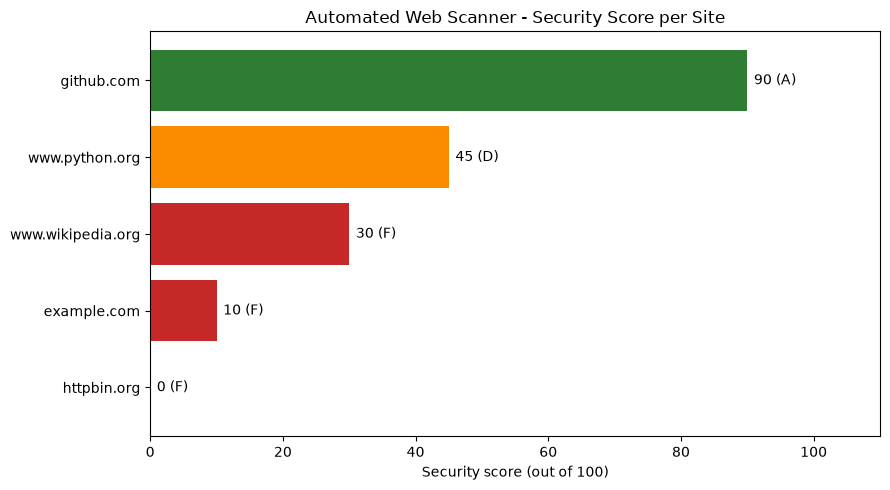

In [18]:
colors = {"A": "#2e7d32", "B": "#7cb342", "C": "#fbc02d", "D": "#fb8c00", "F": "#c62828"}
plot_df = df.sort_values("Score")

plt.figure(figsize=(9, 5))
bars = plt.barh(plot_df["Site"], plot_df["Score"], color=[colors[g] for g in plot_df["Grade"]])
for bar, g, s in zip(bars, plot_df["Grade"], plot_df["Score"]):
    plt.text(s + 1, bar.get_y() + bar.get_height() / 2, f"{s} ({g})", va="center")
plt.xlim(0, 110)
plt.xlabel("Security score (out of 100)")
plt.title("Automated Web Scanner - Security Score per Site")
plt.tight_layout()
plt.savefig("security_scores.png", dpi=150)
plt.show()

## 8. Chart: which headers are missing most often

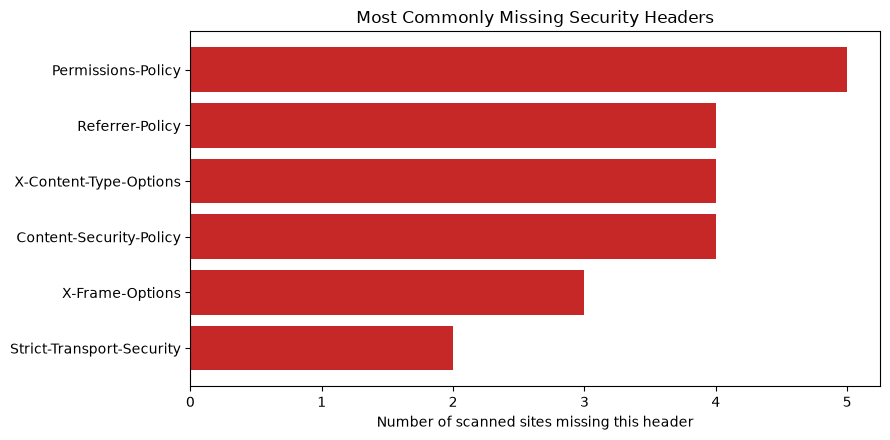

In [19]:
missing = {h: (df[h] == "MISSING").sum() for h in SECURITY_HEADERS}
missing = pd.Series(missing).sort_values()

plt.figure(figsize=(9, 4.5))
plt.barh(missing.index, missing.values, color="#c62828")
plt.xlabel("Number of scanned sites missing this header")
plt.title("Most Commonly Missing Security Headers")
plt.xticks(range(0, len(df) + 1))
plt.tight_layout()
plt.savefig("missing_headers.png", dpi=150)
plt.show()

## 9. Recommendations and CSV report

In [20]:
print("RECOMMENDATIONS\n" + "=" * 60)
for _, row in df.iterrows():
    gaps = [h for h in SECURITY_HEADERS if row[h] == "MISSING"]
    print(f"\n{row['Site']}  ->  Score {row['Score']}/100  (Grade {row['Grade']})")
    if not gaps:
        print("  All checked headers are present. Good job!")
    for h in gaps:
        print(f"  - Add '{h}': {SECURITY_HEADERS[h]['why']}")
    if row["CORS Status"] not in ("SAFE", "UNKNOWN"):
        print(f"  - CORS issue ({row['CORS Status']}): {row['CORS Note']}")

df.to_csv("scan_results.csv", index=False)
print("\nSaved: scan_results.csv, security_scores.png, missing_headers.png")

RECOMMENDATIONS

example.com  ->  Score 10/100  (Grade F)
  - Add 'Strict-Transport-Security': Forces browsers to use HTTPS (stops downgrade / SSL-strip attacks).
  - Add 'Content-Security-Policy': Controls which scripts/resources can load (main defence against XSS).
  - Add 'X-Frame-Options': Stops the site being embedded in an iframe (clickjacking protection).
  - Add 'X-Content-Type-Options': Value 'nosniff' stops browsers guessing file types (MIME sniffing).
  - Add 'Referrer-Policy': Controls how much URL information is leaked to other sites.
  - Add 'Permissions-Policy': Limits access to camera, microphone, location and other browser features.

httpbin.org  ->  Score 0/100  (Grade F)
  - Add 'Strict-Transport-Security': Forces browsers to use HTTPS (stops downgrade / SSL-strip attacks).
  - Add 'Content-Security-Policy': Controls which scripts/resources can load (main defence against XSS).
  - Add 'X-Frame-Options': Stops the site being embedded in an iframe (clickjacking protect

## 10. Conclusion
The scanner automatically audits any list of websites for six key security headers and basic CORS misconfigurations, then produces a score, grade, charts and a CSV report. 

**Future improvements:** cookie flag checks (`Secure`, `HttpOnly`, `SameSite`), TLS certificate checks, scanning many pages per site, and exporting an HTML/PDF report.